# GPT-Image-2 image Transparency


### Installing Required Libraries

In [ ]:
%pip install -q openai pillow python-dotenv azure-identity

### Setting up the Environment

In [1]:
from pathlib import Path
from dotenv import load_dotenv
import os

load_dotenv()

AZURE_OPENAI_ENDPOINT = os.getenv("AZURE_OPENAI_ENDPOINT")

AZURE_OPENAI_IMAGE_DEPLOYMENT = os.getenv("AZURE_OPENAI_IMAGE_DEPLOYMENT")

print(AZURE_OPENAI_ENDPOINT)
print(AZURE_OPENAI_IMAGE_DEPLOYMENT)

https://udemo-103-resource.services.ai.azure.com/openai/v1
gpt-image-2


### Creating the open ai client

In [2]:
from openai import OpenAI
from azure.identity import DefaultAzureCredential, get_bearer_token_provider

token_provider = get_bearer_token_provider(
    DefaultAzureCredential(exclude_environment_credential=True,
                           exclude_managed_identity_credential=True),
    "https://cognitiveservices.azure.com/.default"
)

client = OpenAI(
    base_url=AZURE_OPENAI_ENDPOINT,
    api_key=token_provider(),
)

### Helpers: save + display

In [3]:
import base64
from datetime import datetime
from PIL import Image

OUTPUT_DIR = Path("images")
OUTPUT_DIR.mkdir(exist_ok=True)


def save_b64_image(b64_data: str, filename: str) -> Path:
    out = OUTPUT_DIR / filename
    out.write_bytes(base64.b64decode(b64_data))
    return out


def show(path: Path):
    display(Image.open(path))

### Generate an Image with Transparent Background

C:\Users\jhussein\AppData\Local\Temp\ipykernel_23780\1433945294.py:19: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  f"transparent_banana_{datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.png",


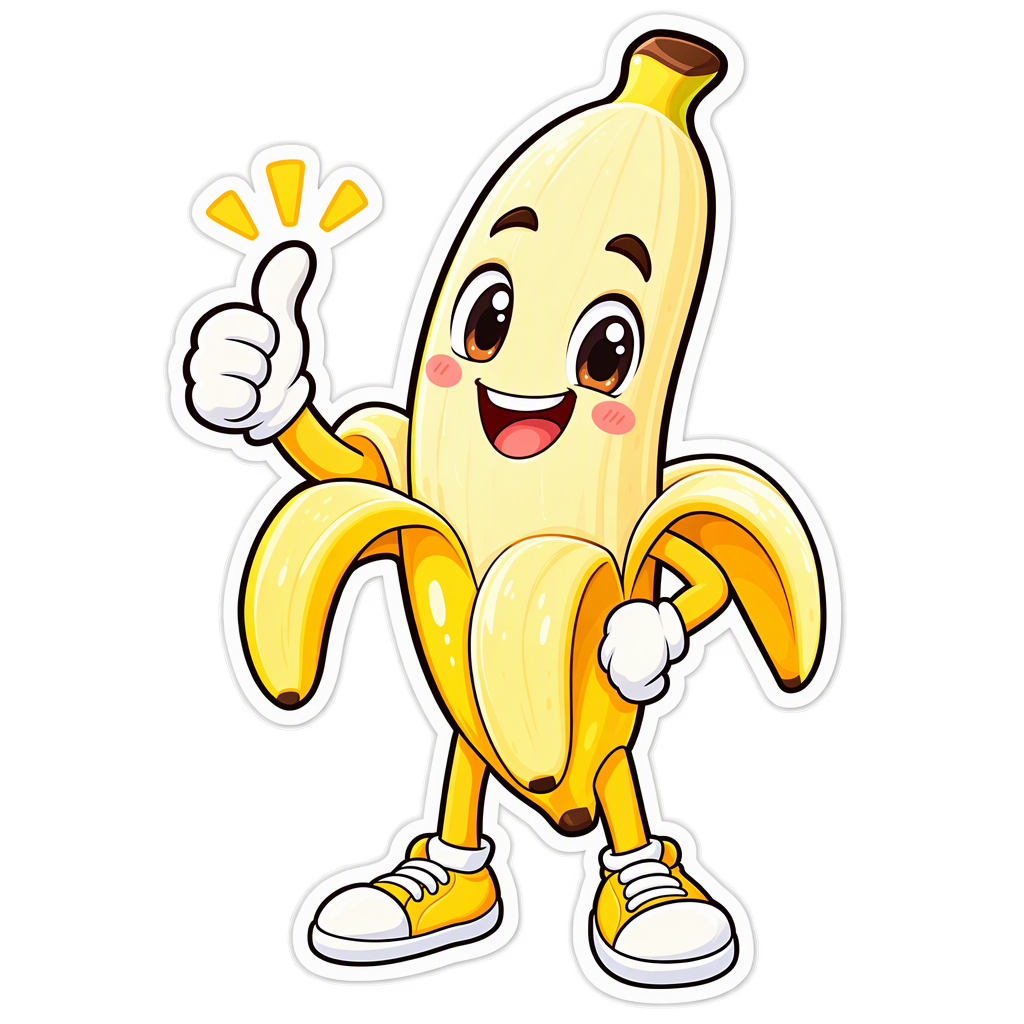

In [4]:
from datetime import datetime

prompt = (
    "A cute cartoon banana mascot, standing and smiling, "
    "sticker style"
)

result = client.images.generate(
    model=AZURE_OPENAI_IMAGE_DEPLOYMENT,
    prompt=prompt,
    size="1024x1024",
    quality="high",
    output_format="png",
    background="transparent",
)

path = save_b64_image(
    result.data[0].b64_json,
    f"transparent_banana_{datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.png",
)

show(path)

### Verify Transparency



In [5]:
img = Image.open(path)

print("Mode:", img.mode)

Mode: RGBA


### Remove Background from an Existing Image

C:\Users\jhussein\AppData\Local\Temp\ipykernel_23780\2690775865.py:20: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  f"transparent_edit_{datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.png",


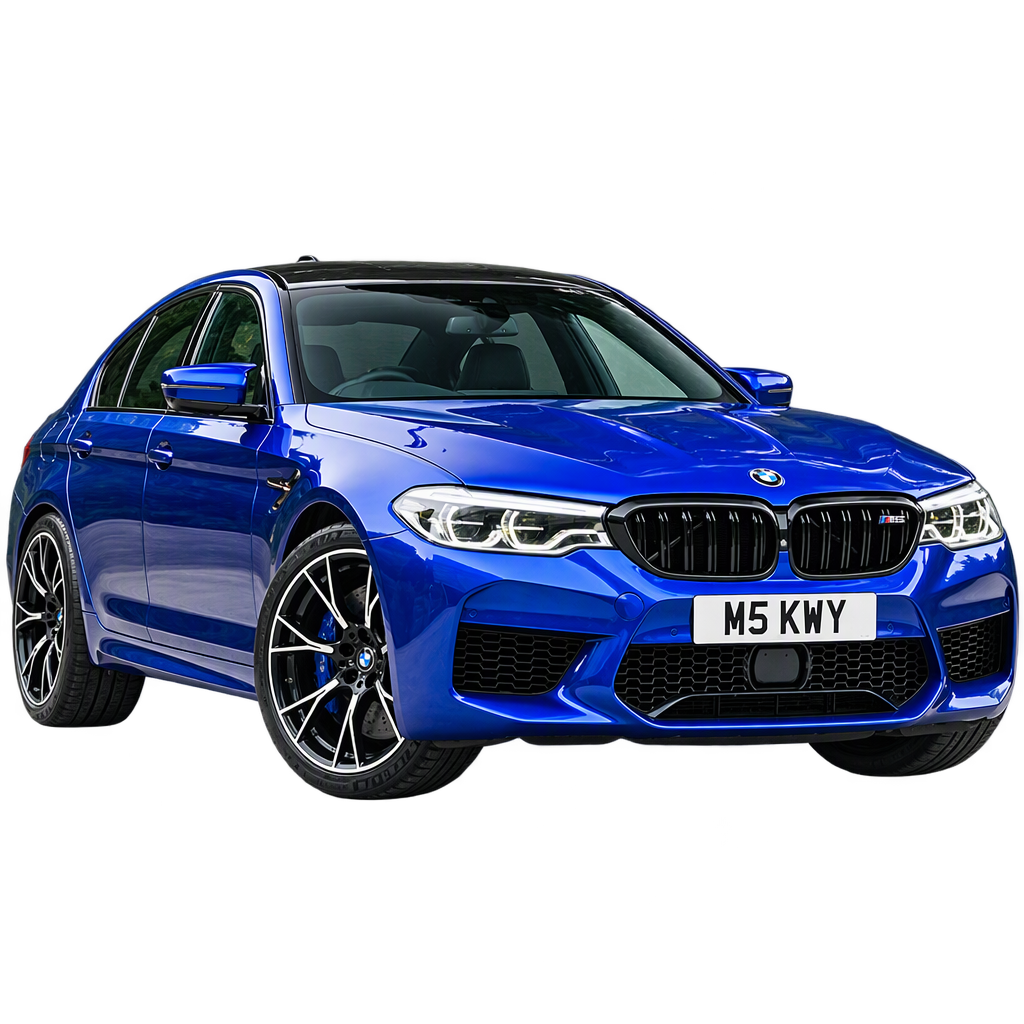

Mode: RGBA


In [10]:
from datetime import datetime

source_image = open("images/sample.png", "rb")

result = client.images.edit(
    model=AZURE_OPENAI_IMAGE_DEPLOYMENT,
    image=source_image,
    prompt=(
        "Remove the background completely. "
        "Keep the main subject unchanged. "
        "Output a transparent PNG."
    ),
    size="1024x1024",
    background="transparent",
    output_format="png",
)

path = save_b64_image(
    result.data[0].b64_json,
    f"transparent_edit_{datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.png",
)

show(path)

img = Image.open(path)
print("Mode:", img.mode)

### Replace Background Instead of Removing It

C:\Users\jhussein\AppData\Local\Temp\ipykernel_23780\2489231034.py:17: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  f"transparent_edit_{datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.png",


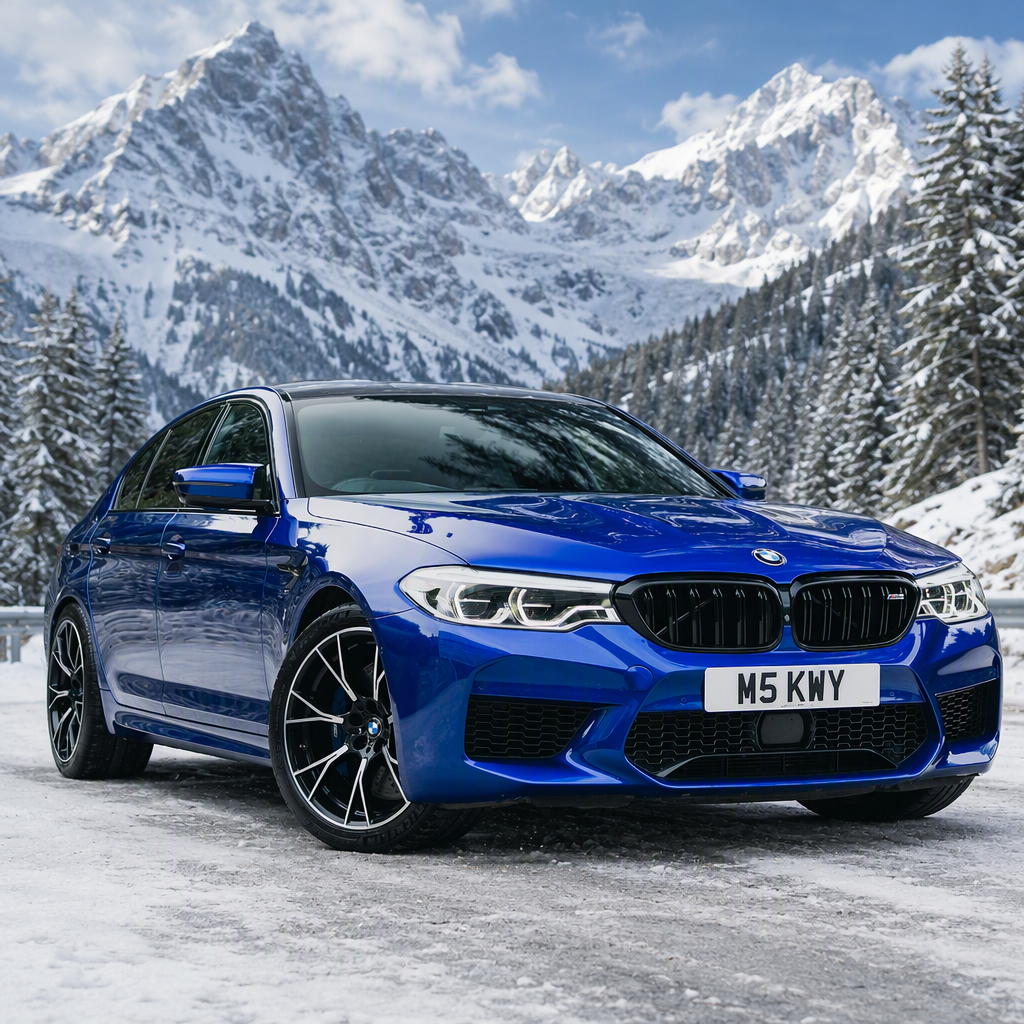

Mode: RGB


In [11]:
from datetime import datetime

source_image = open("images/sample.png", "rb")

result = client.images.edit(
    model=AZURE_OPENAI_IMAGE_DEPLOYMENT,
    image=source_image,
    prompt=(
        "Replace the background with a snowy mountain landscape."
        "Keep the main subject unchanged."
    ),
    size="1024x1024",
)

path = save_b64_image(
    result.data[0].b64_json,
    f"transparent_edit_{datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.png",
)

show(path)

img = Image.open(path)
print("Mode:", img.mode)